## Read the tissue positions and metadata file
This gives us information on the format of pixel value coordinates.
It also gives us an info on outliers and e.g. how many negative examples entries in the y-position-column there are. 

In [24]:
tissuepositions

NameError: name 'tissuepositions' is not defined

In [ ]:
print("positive pixel values: ", len(tissuepositions[tissuepositions["pxl_col_in_fullres"] > 0]))
print("negative pixel values: ", len(tissuepositions[tissuepositions["pxl_col_in_fullres"] < 0]))
print("in_tissue == 1: ", len(tissuepositions[tissuepositions["in_tissue"] == 1]))
print("in_tissue == 0: ", len(tissuepositions[tissuepositions["in_tissue"] == 0]))

positive pixel values:  698148
negative pixel values:  4096
in_tissue == 1:  507684
in_tissue == 0:  194560


In [ ]:
col = "pxl_col_in_fullres"
smallest_gt_zero = tissuepositions.loc[tissuepositions[col] > 0, col].min()
print(f"Smallest positive value in {col}: {smallest_gt_zero}")

smallest_gt_zero = tissuepositions.loc[tissuepositions[col] > 0, col].max()
print(f"Biggest positive value in {col}: {smallest_gt_zero}")

Smallest positive value in pxl_col_in_fullres: 0.01616907989636651
Biggest positive value in pxl_col_in_fullres: 24440.315118149927


## IDK what this does

In [ ]:
# Count occurrences of each id
id_count_check = len(results["id"].unique())
id_count = results["id"].value_counts()
print("Unique IDs found in the results:", id_count_check)  # List of unique IDs
print("Counts of each ID:", id_count)  # Counts of each ID

# Filter brands that occur more than once
ids_more_than_once = id_count[id_count > 1]

# If you want just the list of brand names:
id_label = ids_more_than_once.index.tolist()

# If you want the number of such brands:
number_of_ids = len(ids_more_than_once)

print("IDs appearing more than once:")
print(ids_more_than_once)       # brand name and counts
#print(id_label)                 # just brand names
print("Number of Ids: ", number_of_ids)           # count of brands appearing more than once


Unique IDs found in the results: 110016
Counts of each ID: id
ID_85299     7
ID_534315    5
ID_381216    5
ID_84659     5
ID_276597    5
            ..
ID_391996    1
ID_390550    1
ID_391503    1
ID_390132    1
ID_388651    1
Name: count, Length: 110016, dtype: int64
IDs appearing more than once:
id
ID_85299     7
ID_534315    5
ID_381216    5
ID_84659     5
ID_276597    5
            ..
ID_54843     2
ID_535021    2
ID_531992    2
ID_401223    2
ID_540878    2
Name: count, Length: 3687, dtype: int64
Number of Ids:  3687


In [ ]:
import pandas as pd
df1 = pd.read_csv("uni/notebooks/metadata/WSI_patch_metadata1.csv")
df2 = pd.read_csv("uni/notebooks/metadata/WSI_patch_metadata2.csv")

merged_df = pd.concat([df1, df2], axis=0, ignore_index=True)

merged_df.to_csv("uni/notebooks/metadata/WSI_patch_metadata.csv", index=False)

In [ ]:
import scanpy as sc
import anndata as ad

# Load both .h5ad files
adata1 = sc.read_h5ad("uni/notebooks/metadata/WSI_patch_embeddings1.h5ad")
adata2 = sc.read_h5ad("uni/notebooks/metadata/WSI_patch_embeddings2.h5ad")

# Concatenate along observations (rows)
adata_merged = ad.concat([adata1, adata2], axis=0, join="outer")  
# join="outer" keeps all obs/var, join="inner" keeps only common

# Save
adata_merged.write_h5ad("uni/notebooks/metadata/WSI_patch_embeddings.h5ad")


## Checking coordinates of filtered patches and Nuclei

In [ ]:
import os
import scanpy as sc
import pandas as pd
import geopandas as gpd


person = "CRC_P1"
bin_size = "002um"

uni_folder = "uni/notebooks/metadata"
uni_patch_embeddings_filename = "filtered_WSI_patch_embeddings.h5ad"

cell_seg_folder = f"Cell_Segmentation/output/{person}/{bin_size}/custom_binning"
filtered_bins_filename = "filtered_custom_bins.h5ad"
nuclei_genes_filtered_filename = "count_area_filtered_adata.h5ad"
nuclei_polys_filename = "nuclei_geometry.parquet"

In [ ]:
# Loading the data
adata_patches = sc.read_h5ad(os.path.join(uni_folder, uni_patch_embeddings_filename))
#adata_bins = sc.read_h5ad(os.path.join(cell_seg_folder, filtered_bins_filename))
nuclei_positions = gpd.read_parquet(os.path.join(cell_seg_folder, nuclei_polys_filename))
adata_filtered_nuclei = sc.read_h5ad(os.path.join(cell_seg_folder, nuclei_genes_filtered_filename))

# merge nuclei positions with adata_filtered_nuclei
adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.merge(nuclei_positions, on="id", how="left")


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [ ]:
print("Min x:", adata_patches.obs.loc[adata_patches.obs["Slide_ID"]==person, "X"].min())
print("Max x:", adata_patches.obs.loc[adata_patches.obs["Slide_ID"]==person, "X"].max())
print("Min y:", adata_patches.obs.loc[adata_patches.obs["Slide_ID"]==person, "Y"].min())
print("Max y:", adata_patches.obs.loc[adata_patches.obs["Slide_ID"]==person, "Y"].max())

Min x: 448
Max x: 24192


In [ ]:
# filter rows/columns > 0
row_vals = tissuepositions.loc[tissuepositions['pxl_row_in_fullres'] > 0, 'pxl_row_in_fullres']
col_vals = tissuepositions.loc[tissuepositions['pxl_col_in_fullres'] > 0, 'pxl_col_in_fullres']

# compute min and max
min_row, max_row = row_vals.min(), row_vals.max()
min_col, max_col = col_vals.min(), col_vals.max()

print(f"Row -> min > 0: {min_row}, max: {max_row}")
print(f"Column -> min > 0: {min_col}, max: {max_col}")

Row -> min > 0: 12137.797400349906, max: 36828.94892524755
Column -> min > 0: 0.0003797818750692132, max: 24436.630813568463


In [ ]:
import scanpy as sc
import pandas as pd
import os

h5ad_test = sc.read_h5ad("Cell_Segmentation/output/merged_custom_binning/filtered_custom_bins.h5ad")

In [ ]:
import scanpy as sc
import pandas as pd
import geopandas as gpd

person = "CRC_P1"
bin_size = "002um"

adata_filtered_nuclei = sc.read_h5ad("Cell_Segmentation/output/merged_custom_binning/002um/count_area_filtered_adata.h5ad")
nuclei_positions = gpd.read_parquet("Cell_Segmentation/output/merged_custom_binning/002um/nuclei_geometry.parquet")

#adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.merge(nuclei_positions, on=["id", "Slide_ID"], how="left")
adata_filtered_nuclei.obs = adata_filtered_nuclei.obs.merge(nuclei_positions, on=["Slide_ID", "id"], how="left")
adata_filtered_nuclei = adata_filtered_nuclei[adata_filtered_nuclei.obs["Slide_ID"] == person]


# gives us the overview over each nucleus for each person, with its geometry
# adata_filtered_nuclei.obs

In [ ]:
nuclei_positions = nuclei_positions[nuclei_positions["Slide_ID"] == person]
# nuclei_positions

# Get the bounding box of the whole dataset
minx, miny, maxx, maxy = nuclei_positions.total_bounds

print("Bounds from Nuclei Positiosn Parquet file:")
print("Min X:", minx)
print("Min Y:", miny)
print("Max X:", maxx)
print("Max Y:", maxy)


minx2, miny2, maxx2, maxy2 = adata_filtered_nuclei.total_bounds

print("Bounds from merged adata file:")
print("Min X:", minx2)
print("Min Y:", miny2)
print("Max X:", maxx2)
print("Max Y:", maxy2)


Bounds from Nuclei Positiosn Parquet file:
Min X: 680.6541748046875
Min Y: 14102.367919921875
Max X: 24408.420166015625
Max Y: 36828.15768432617
Bounds from merged adata file:
Min X: 680.6541748046875
Min Y: 14102.367919921875
Max X: 24408.420166015625
Max Y: 36828.15768432617


# Check Anndata structure for Uni and StarDist

In [ ]:
import scanpy as sc
import geopandas as gpd

In [ ]:
unidata_multi = sc.read_h5ad("uni/notebooks/metadata/filtered_WSI_patch_embeddings.h5ad")
unidata_multi.obs

,Slide_ID,Patch_ID,X,Y,leiden_0.2,leiden_0.5,leiden_1.0,leiden_2.0
CRC_P1_patch_295.png,CRC_P1,patch_295.png,448,28713,6,5,5,8
CRC_P1_patch_296.png,CRC_P1,patch_296.png,448,28937,6,5,5,25
CRC_P1_patch_297.png,CRC_P1,patch_297.png,448,29161,6,5,5,25
CRC_P1_patch_298.png,CRC_P1,patch_298.png,448,29385,6,5,5,25
CRC_P1_patch_299.png,CRC_P1,patch_299.png,448,29609,6,5,5,25
...,...,...,...,...,...,...,...,...
Normal_P5_patch_11877.png,Normal_P5,patch_11877.png,65876,49773,1,1,2,2
Normal_P5_patch_11878.png,Normal_P5,patch_11878.png,65876,49997,1,1,2,2
Normal_P5_patch_11879.png,Normal_P5,patch_11879.png,65876,50221,1,1,2,2
Normal_P5_patch_11880.png,Normal_P5,patch_11880.png,65876,50445,1,1,2,2


In [ ]:
person = "CRC_P1"
single_countareafilteredadata = sc.read_h5ad("Cell_Segmentation/output/CRC_P1/002um/custom_binning/count_area_filtered_adata.h5ad")
single_countareafilteredadata.obs

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,id,Slide_ID,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,clusters
5,ID_52421,CRC_P1,97,4.584967,112.0,4.727388,58.035714,100.000000,100.000000,100.0,1
13,ID_52429,CRC_P1,106,4.672829,121.0,4.804021,53.719008,95.041322,100.000000,100.0,1
23,ID_52439,CRC_P1,136,4.919981,149.0,5.010635,42.281879,75.838926,100.000000,100.0,1
31,ID_52447,CRC_P1,88,4.488636,137.0,4.927254,72.262774,100.000000,100.000000,100.0,1
35,ID_52451,CRC_P1,95,4.564348,111.0,4.718499,59.459459,100.000000,100.000000,100.0,1
...,...,...,...,...,...,...,...,...,...,...,...
289375,ID_735550,CRC_P1,119,4.787492,127.0,4.852030,45.669291,85.039370,100.000000,100.0,0
289378,ID_735647,CRC_P1,94,4.553877,105.0,4.663439,58.095238,100.000000,100.000000,100.0,0
289383,ID_735866,CRC_P1,111,4.718499,142.0,4.962845,57.042254,92.253521,100.000000,100.0,2
289391,ID_736660,CRC_P1,85,4.454347,120.0,4.795791,70.833333,100.000000,100.000000,100.0,2


In [ ]:
multi_countareafilteredadata = sc.read_h5ad("Cell_Segmentation/output/merged_custom_binning/002um/count_area_filtered_adata.h5ad")
multi_countareafilteredadata.obs

,id,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,clusters,Slide_ID
CRC_P1_5,ID_52421,97,4.584967,112.0,4.727388,58.035714,100.000000,100.000000,100.000000,1,CRC_P1
CRC_P1_13,ID_52429,106,4.672829,121.0,4.804021,53.719008,95.041322,100.000000,100.000000,1,CRC_P1
CRC_P1_23,ID_52439,136,4.919981,149.0,5.010635,42.281879,75.838926,100.000000,100.000000,1,CRC_P1
CRC_P1_31,ID_52447,88,4.488636,137.0,4.927254,72.262774,100.000000,100.000000,100.000000,1,CRC_P1
CRC_P1_35,ID_52451,95,4.564348,111.0,4.718499,59.459459,100.000000,100.000000,100.000000,1,CRC_P1
...,...,...,...,...,...,...,...,...,...,...,...
Normal_P5_222609,ID_666491,117,4.770685,138.0,4.934474,51.449275,87.681159,100.000000,100.000000,1,Normal_P5
Normal_P5_222610,ID_666492,144,4.976734,370.0,5.916202,74.594595,88.108108,100.000000,100.000000,0,Normal_P5
Normal_P5_222613,ID_666496,561,6.331502,726.0,6.588926,25.482094,36.501377,50.275482,91.597796,0,Normal_P5
Normal_P5_222614,ID_666497,158,5.068904,182.0,5.209486,40.659341,68.131868,100.000000,100.000000,0,Normal_P5


In [ ]:
single_filteredcustombins = sc.read_h5ad("Cell_Segmentation/output/CRC_P1/002um/custom_binning/filtered_custom_bins.h5ad")
single_filteredcustombins.obs

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,index_x,index_y,id,is_within_polygon,is_not_in_an_polygon_overlap,Slide_ID
s_002um_01867_02041-1,1,1867,2041,23101.556076,14781.241485,s_002um_01867_02041-1,s_002um_01867_02041-1,ID_239410,True,True,CRC_P1
s_002um_02109_01204-1,1,2109,1204,21277.315954,8684.120489,s_002um_02109_01204-1,s_002um_02109_01204-1,ID_146203,True,True,CRC_P1
s_002um_02496_03085-1,1,2496,3085,18576.619085,22449.992628,s_002um_02496_03085-1,s_002um_02496_03085-1,ID_172530,True,True,CRC_P1
s_002um_00481_01245-1,1,481,1245,33172.972720,8872.760237,s_002um_00481_01245-1,s_002um_00481_01245-1,ID_524803,True,True,CRC_P1
s_002um_00727_01427-1,1,727,1427,31388.196866,10218.836278,s_002um_00727_01427-1,s_002um_00727_01427-1,ID_383635,True,True,CRC_P1
...,...,...,...,...,...,...,...,...,...,...,...
s_002um_01041_01763-1,1,1041,1763,29117.030951,12694.396181,s_002um_01041_01763-1,s_002um_01041_01763-1,ID_303658,True,True,CRC_P1
s_002um_01051_01858-1,1,1051,1858,29050.385985,13388.973597,s_002um_01051_01858-1,s_002um_01051_01858-1,ID_299704,True,True,CRC_P1
s_002um_02298_02981-1,1,2298,2981,20016.140671,21676.806463,s_002um_02298_02981-1,s_002um_02298_02981-1,ID_171887,True,True,CRC_P1
s_002um_01377_01056-1,1,1377,1056,26614.803940,7553.299400,s_002um_01377_01056-1,s_002um_01377_01056-1,ID_290533,True,True,CRC_P1


In [ ]:
multi_filteredcustombins = sc.read_h5ad("Cell_Segmentation/output/merged_custom_binning/002um/filtered_custom_bins.h5ad")
multi_filteredcustombins.obs

,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,index_x,index_y,id,is_within_polygon,is_not_in_an_polygon_overlap,Slide_ID
CRC_P1_s_002um_01867_02041-1,1,1867,2041,23101.556076,14781.241485,s_002um_01867_02041-1,s_002um_01867_02041-1,ID_239410,True,True,CRC_P1
CRC_P1_s_002um_02109_01204-1,1,2109,1204,21277.315954,8684.120489,s_002um_02109_01204-1,s_002um_02109_01204-1,ID_146203,True,True,CRC_P1
CRC_P1_s_002um_02496_03085-1,1,2496,3085,18576.619085,22449.992628,s_002um_02496_03085-1,s_002um_02496_03085-1,ID_172530,True,True,CRC_P1
CRC_P1_s_002um_00481_01245-1,1,481,1245,33172.972720,8872.760237,s_002um_00481_01245-1,s_002um_00481_01245-1,ID_524803,True,True,CRC_P1
CRC_P1_s_002um_00727_01427-1,1,727,1427,31388.196866,10218.836278,s_002um_00727_01427-1,s_002um_00727_01427-1,ID_383635,True,True,CRC_P1
...,...,...,...,...,...,...,...,...,...,...,...
Normal_P5_s_002um_00804_03277-1,1,804,3277,32351.711109,42237.213333,s_002um_00804_03277-1,s_002um_00804_03277-1,ID_396224,True,True,Normal_P5
Normal_P5_s_002um_01533_01973-1,1,1533,1973,37690.479472,51755.407138,s_002um_01533_01973-1,s_002um_01533_01973-1,ID_498911,True,True,Normal_P5
Normal_P5_s_002um_00296_02357-1,1,296,2357,28650.366640,48963.184135,s_002um_00296_02357-1,s_002um_00296_02357-1,ID_315195,True,True,Normal_P5
Normal_P5_s_002um_01141_01847-1,1,1141,1847,34828.311124,52679.930388,s_002um_01141_01847-1,s_002um_01141_01847-1,ID_416686,True,True,Normal_P5


In [ ]:
single_polys = gpd.read_parquet("Cell_Segmentation/output/CRC_P1/002um/custom_binning/nuclei_geometry.parquet")
single_polys

,id,geometry,Slide_ID
5,ID_52421,"POLYGON ((14490.007 14852.000, 14490.093 14853...",CRC_P1
13,ID_52429,"POLYGON ((14409.892 14808.000, 14408.815 14810...",CRC_P1
23,ID_52439,"POLYGON ((14437.344 14816.000, 14434.664 14818...",CRC_P1
31,ID_52447,"POLYGON ((14055.935 14792.000, 14055.610 14793...",CRC_P1
35,ID_52451,"POLYGON ((14464.044 14820.000, 14464.270 14822...",CRC_P1
...,...,...,...
289375,ID_735550,"POLYGON ((23650.012 36770.000, 23649.842 36772...",CRC_P1
289378,ID_735647,"POLYGON ((23570.196 36782.000, 23568.974 36783...",CRC_P1
289383,ID_735866,"POLYGON ((21905.758 36780.000, 21906.443 36782...",CRC_P1
289391,ID_736660,"POLYGON ((23536.900 36800.000, 23537.887 36801...",CRC_P1


In [ ]:
multi_polys = gpd.read_parquet("Cell_Segmentation/output/merged_custom_binning/002um/nuclei_geometry.parquet")
multi_polys

,id,geometry,Slide_ID
0,ID_52421,"POLYGON ((14490.007 14852.000, 14490.093 14853...",CRC_P1
1,ID_52429,"POLYGON ((14409.892 14808.000, 14408.815 14810...",CRC_P1
2,ID_52439,"POLYGON ((14437.344 14816.000, 14434.664 14818...",CRC_P1
3,ID_52447,"POLYGON ((14055.935 14792.000, 14055.610 14793...",CRC_P1
4,ID_52451,"POLYGON ((14464.044 14820.000, 14464.270 14822...",CRC_P1
...,...,...,...
456876,ID_666491,"POLYGON ((52314.505 45776.000, 52314.601 45776...",Normal_P5
456877,ID_666492,"POLYGON ((51664.354 46284.000, 51664.362 46284...",Normal_P5
456878,ID_666496,"POLYGON ((52024.459 46084.000, 52024.903 46084...",Normal_P5
456879,ID_666497,"POLYGON ((51702.852 45716.000, 51702.877 45716...",Normal_P5


In [ ]:
assigned_nuclei = sc.read_h5ad("Cell_Segmentation/output/merged_custom_binning/002um/patch_assigned_count_area_filtered_adata.h5ad")
assigned_nuclei.obs

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


,id,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,clusters,Slide_ID,Patch_ID
0,ID_52421,97,4.584967,112.0,4.727388,58.035714,100.000000,100.000000,100.000000,1,CRC_P1,patch_7053.png
1,ID_52429,106,4.672829,121.0,4.804021,53.719008,95.041322,100.000000,100.000000,1,CRC_P1,patch_7052.png
2,ID_52439,136,4.919981,149.0,5.010635,42.281879,75.838926,100.000000,100.000000,1,CRC_P1,patch_7052.png
3,ID_52447,88,4.488636,137.0,4.927254,72.262774,100.000000,100.000000,100.000000,1,CRC_P1,patch_6832.png
4,ID_52451,95,4.564348,111.0,4.718499,59.459459,100.000000,100.000000,100.000000,1,CRC_P1,patch_7052.png
...,...,...,...,...,...,...,...,...,...,...,...,...
456876,ID_666491,117,4.770685,138.0,4.934474,51.449275,87.681159,100.000000,100.000000,1,Normal_P5,patch_5210.png
456877,ID_666492,144,4.976734,370.0,5.916202,74.594595,88.108108,100.000000,100.000000,0,Normal_P5,patch_4885.png
456878,ID_666496,561,6.331502,726.0,6.588926,25.482094,36.501377,50.275482,91.597796,0,Normal_P5,patch_5102.png
456879,ID_666497,158,5.068904,182.0,5.209486,40.659341,68.131868,100.000000,100.000000,0,Normal_P5,patch_4882.png


# What adata contains what

The files are listed in the order of creation in "CustomBinning.ipynb".

In [17]:
import scanpy as sc
import os
import geopandas as gpd
import pandas as pd

data_path = "Cell_Segmentation/output/CRC_P5/002um/custom_binning"
data_path2 = "Cell_Segmentation/output/merged_custom_binning/002um"

**1.**  
**filtered_custom_bins.h5ad**  
We filter out any barcodes (bins), that are either in no nucleus or are in multiple nuclei at once (overlapping).
The resulting matrix contains all expressed genes per **bin**, not per nucleus.
- `.X`: rows (obs): Barcodes per one nucleus, Columns (var):	Genes from the 10x matrix, Values: Integer UMI counts
- `.obs`: 'in_tissue', 'array_row', 'array_col', 'pxl_row_in_fullres', 'pxl_col_in_fullres', index_x', 'index_y', 'id', 'is_within_polygon', 'is_not_in_an_polygon_overlap', 'Slide_ID'
- `.var`: 'gene_ids', 'feature_types', 'genome'

In [18]:
filtered_custom_bins = sc.read_h5ad(os.path.join(data_path, "filtered_custom_bins.h5ad"))
filtered_custom_bins

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 1721528 × 18085
    obs: 'in_tissue', 'array_row', 'array_col', 'pxl_row_in_fullres', 'pxl_col_in_fullres', 'index_x', 'index_y', 'id', 'is_within_polygon', 'is_not_in_an_polygon_overlap', 'Slide_ID'
    var: 'gene_ids', 'feature_types', 'genome'

In [19]:
filtered_custom_bins.obs

,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,index_x,index_y,id,is_within_polygon,is_not_in_an_polygon_overlap,Slide_ID
s_002um_02043_00141-1,1,2043,141,49055.614563,45360.824978,s_002um_02043_00141-1,s_002um_02043_00141-1,ID_1318569,True,True,CRC_P5
s_002um_03246_01880-1,1,3246,1880,40320.322188,58100.258125,s_002um_03246_01880-1,s_002um_03246_01880-1,ID_1056638,True,True,CRC_P5
s_002um_01050_01530-1,1,1050,1530,56350.990878,55477.439409,s_002um_01050_01530-1,s_002um_01050_01530-1,ID_1620019,True,True,CRC_P5
s_002um_01057_00712-1,1,1057,712,56275.268082,49502.109602,s_002um_01057_00712-1,s_002um_01057_00712-1,ID_1598983,True,True,CRC_P5
s_002um_00737_02449-1,1,737,2449,58665.104485,62181.512805,s_002um_00737_02449-1,s_002um_00737_02449-1,ID_1735286,True,True,CRC_P5
...,...,...,...,...,...,...,...,...,...,...,...
s_002um_01930_00297-1,1,1930,297,49885.719742,46496.957741,s_002um_01930_00297-1,s_002um_01930_00297-1,ID_1312732,True,True,CRC_P5
s_002um_00635_02644-1,1,635,2644,59416.094674,63602.988400,s_002um_00635_02644-1,s_002um_00635_02644-1,ID_1736877,True,True,CRC_P5
s_002um_00080_00956-1,1,80,956,63419.638408,51255.052050,s_002um_00080_00956-1,s_002um_00080_00956-1,ID_1755061,True,True,CRC_P5
s_002um_02017_00654-1,1,2017,654,49260.921104,49107.423831,s_002um_02017_00654-1,s_002um_02017_00654-1,ID_1321331,True,True,CRC_P5


  
**2.**  
**nuclei_grouped_UMI_count.h5ad**  
Structure: nucleus_IDs x embedding diension (i.e. length == no. of all possible expressed genes in nucleus)

- `.X`: unique nucleus IDs (row ID) x genes (**column**: gene ID, **cell**: summed expression of that gene over all bins in the nucleus)
- `obs`: nucleus ID, Slide_ID
- `.var`: gene ID, feature type, genome

In [ ]:
nuclei_grouped_UMI_count = sc.read_h5ad(os.path.join(data_path, "nuclei_grouped_UMI_count.h5ad"))
nuclei_grouped_UMI_count

**3.**  
**count_area_filtered_adata.h5ad**  
Builds on the previous anndata, but applies filters both to *nucleus area* and *gene expression*.  
We remove nuclei with an area larger than a threshold (i.e. 500), to avoid broken or merged nuclei.  
We also remove nuclei with a UMI count below a threshold. --> avoid empty or low-quality nuclei  
- `.X`: same as `nuclei_grouped_UMI_count`
- `.obs`: 'id', 'Slide_ID', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'clusters'
- `.var`: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
- `uns`: 'clusters', 'hvg', 'log1p', 'neighbors', 'pca'
- `obsm`: 'X_pca'
- `varm`: 'PCs'
- `obsp`: 'connectivities', 'distances'

In [12]:
count_area_filtered_adata = sc.read_h5ad(os.path.join(data_path, "count_area_filtered_adata.h5ad"))
count_area_filtered_adata.obs

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,id,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,clusters,Slide_ID
3,ID_1040398,225,5.420535,242.0,5.493061,27.685950,48.347107,89.669421,100.0,0,CRC_P5
4,ID_1040399,56,4.043051,159.0,5.075174,96.226415,100.000000,100.000000,100.0,0,CRC_P5
9,ID_1040404,179,5.192957,188.0,5.241747,31.382979,57.978723,100.000000,100.0,0,CRC_P5
10,ID_1040405,279,5.634790,338.0,5.826000,32.248521,47.041420,76.627219,100.0,0,CRC_P5
11,ID_1040409,133,4.897840,161.0,5.087596,48.447205,79.503106,100.000000,100.0,0,CRC_P5
...,...,...,...,...,...,...,...,...,...,...,...
270971,ID_1773080,318,5.765191,421.0,6.045005,36.342043,48.218527,71.971496,100.0,3,CRC_P5
270972,ID_1773081,227,5.429346,297.0,5.697093,40.404040,57.239057,90.909091,100.0,1,CRC_P5
270974,ID_1773083,173,5.159055,210.0,5.351858,41.428571,65.238095,100.000000,100.0,6,CRC_P5
270976,ID_1773086,99,4.605170,105.0,4.663439,53.333333,100.000000,100.000000,100.0,9,CRC_P5


In [ ]:
count_area_filtered_adata.var_names[count_area_filtered_adata.var_names.duplicated()]

Index(['TBCE', 'HSPA14', 'TMSB15B'], dtype='object')

In [ ]:
count_area_filtered_adata.var[count_area_filtered_adata.var_names == "TBCE"]

,gene_ids,feature_types,genome,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,highly_variable,means,dispersions,dispersions_norm
TBCE,ENSG00000285053,Gene Expression,GRCh38,237,0.004021,0.004013,99.599608,238.0,5.476464,False,0.003434,0.002397,-0.343069
TBCE,ENSG00000284770,Gene Expression,GRCh38,191,0.003244,0.003238,99.677321,192.0,5.262690,False,0.002547,-0.053013,-0.694714


**4.**  
**patch_assigned_count_area_filtered_adata.h5ad**  
Completely same structure as count_area_filtered_adata.h5ad. 
However, .obs now has a column that assigns it to a certain image patch from the original image.

- `.X`:
- `.obs`: 'id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'clusters', 'Slide_ID', 'Patch_ID'
- `.var`: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
- `.obsm`: 'X_pca'
- `.varm`: 'PCs'

In [ ]:
patch_assigned_count_area_filtered_adata = sc.read_h5ad(os.path.join(data_path2, "patch_assigned_count_area_filtered_adata.h5ad"))
patch_assigned_count_area_filtered_adata

**5.**  
**nuclei_geometry.parquet**
Contains nuclei geometry for each nucleus.

Structure columns: nucleus ID, geometry, Slide_ID


In [8]:
nuclei_geometry = pd.read_parquet(os.path.join(data_path, "nuclei_geometry.parquet"))
nuclei_geometry

,id,geometry,Slide_ID
3,ID_1040398,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...,CRC_P5
4,ID_1040399,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...,CRC_P5
9,ID_1040404,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...,CRC_P5
10,ID_1040405,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...,CRC_P5
11,ID_1040409,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...,CRC_P5
...,...,...,...
270971,ID_1773080,"b""\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...",CRC_P5
270972,ID_1773081,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...,CRC_P5
270974,ID_1773083,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...,CRC_P5
270976,ID_1773086,"b""\x01\x03\x00\x00\x00\x01\x00\x00\x00!\x00\x0...",CRC_P5


# check data spagcn

In [1]:
import scanpy as sc

test = sc.read_h5ad("../SpaGCN/data/sample_data.h5ad")
test.obs

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,x1,x2,x3,x4,x5
AAACAAGTATCTCCCA-1,1,50,102,8468,9791
AAACAATCTACTAGCA-1,1,3,43,2807,5769
AAACACCAATAACTGC-1,1,59,19,9505,4068
AAACAGAGCGACTCCT-1,1,14,94,4151,9271
AAACAGCTTTCAGAAG-1,1,43,9,7583,3393
...,...,...,...,...,...
TTGTTTCACATCCAGG-1,1,58,42,9396,5653
TTGTTTCATTAGTCTA-1,1,60,30,9630,4825
TTGTTTCCATACAACT-1,1,45,27,7831,4631
TTGTTTGTATTACACG-1,1,73,41,11193,5571


In [3]:
test

AnnData object with n_obs × n_vars = 3639 × 33538
    obs: 'x1', 'x2', 'x3', 'x4', 'x5'
    var: 'gene_ids', 'feature_types', 'genome', 'genename'

In [ ]:
array_info = pd.read_parquet("data/CRC_P1/output/binned_outputs/square_002um/spatial/tissue_positions.parquet")
array_info

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,36602.550726,-253.148794
1,s_002um_00000_00001-1,0,0,1,36602.618323,-245.845230
2,s_002um_00000_00002-1,0,0,2,36602.685920,-238.541664
3,s_002um_00000_00003-1,0,0,3,36602.753517,-231.238099
4,s_002um_00000_00004-1,0,0,4,36602.821115,-223.934533
...,...,...,...,...,...,...
11222495,s_002um_03349_03345-1,1,3349,3345,12362.290802,24407.411661
11222496,s_002um_03349_03346-1,1,3349,3346,12362.357920,24414.716449
11222497,s_002um_03349_03347-1,1,3349,3347,12362.425038,24422.021237
11222498,s_002um_03349_03348-1,1,3349,3348,12362.492155,24429.326025


In [26]:
array_info2 = array_info[array_info["array_row"] == 0]
array_info2

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,36602.550726,-253.148794
1,s_002um_00000_00001-1,0,0,1,36602.618323,-245.845230
2,s_002um_00000_00002-1,0,0,2,36602.685920,-238.541664
3,s_002um_00000_00003-1,0,0,3,36602.753517,-231.238099
4,s_002um_00000_00004-1,0,0,4,36602.821115,-223.934533
...,...,...,...,...,...,...
3345,s_002um_00000_03345-1,1,0,3345,36828.678500,24178.914785
3346,s_002um_00000_03346-1,1,0,3346,36828.746106,24186.219330
3347,s_002um_00000_03347-1,1,0,3347,36828.813713,24193.523876
3348,s_002um_00000_03348-1,1,0,3348,36828.881319,24200.828422


In [27]:
array_info2.shape[0]

3350

In [4]:
import pandas as pd
crc_p1 = pd.read_parquet("data/CRC_P1/output/binned_outputs/square_002um/spatial/tissue_positions.parquet")
crc_p1


,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,36602.550726,-253.148794
1,s_002um_00000_00001-1,0,0,1,36602.618323,-245.845230
2,s_002um_00000_00002-1,0,0,2,36602.685920,-238.541664
3,s_002um_00000_00003-1,0,0,3,36602.753517,-231.238099
4,s_002um_00000_00004-1,0,0,4,36602.821115,-223.934533
...,...,...,...,...,...,...
11222495,s_002um_03349_03345-1,1,3349,3345,12362.290802,24407.411661
11222496,s_002um_03349_03346-1,1,3349,3346,12362.357920,24414.716449
11222497,s_002um_03349_03347-1,1,3349,3347,12362.425038,24422.021237
11222498,s_002um_03349_03348-1,1,3349,3348,12362.492155,24429.326025


In [ ]:
array_x_min = crc_p1["array_col"].min()
array_y_min = crc_p1["array_row"].min()
array_x_max = crc_p1["array_col"].max()
array_y_max = crc_p1["array_row"].max()

pxl_x_min = crc_p1["pxl_col_in_fullres"].min()
pxl_y_min = crc_p1["pxl_row_in_fullres"].min()
pxl_x_max = crc_p1["pxl_col_in_fullres"].max()
pxl_y_max = crc_p1["pxl_row_in_fullres"].max()

print("Minimal pixel value: ", pxl_x_min, pxl_y_min)
print("Maximal pixel value: ", pxl_x_max, pxl_y_max)

print("Minimal array value: ", array_x_min, array_y_min)
print("Maximal array value: ", array_x_max, array_y_max)


Minimal pixel value:  -253.148794489166 12137.797400349906
Maximal pixel value:  24436.630813568463 36828.94892524755
Minimal array value:  0 0
Maximal array value:  3349 3349


In [10]:
crc_p11 = crc_p1[(crc_p1["array_row"] == array_y_max) & (crc_p1["array_col"] == array_x_max)]
crc_p11

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
11222499,s_002um_03349_03349-1,1,3349,3349,12362.559273,24436.630814


# Plottinng the gap.  
Note that array position (0,0) is at the bottom left of the tissue image.  
This correpsonds to pixel position (0, max), as the y-axis is inverted. 

We plot the patch where array = (0,max) and pixel = (min, min)


In [41]:
import pandas as pd 
import scanpy as sc

person = "CRC_P5"

tissue_pos = pd.read_parquet(f"data/{person}/output/binned_outputs/square_002um/spatial/tissue_positions.parquet")
metadata = pd.read_csv("uni/notebooks/metadata/WSI_patch_metadata.csv")

patches = metadata[metadata["Slide_ID"] == person]
x_min = patches["X"].min()
y_min = patches["Y"].min()
patch_path = patches.loc[(patches["X"] == x_min) & (patches["Y"] == y_min), "Path"].iloc[0]
patch_path

'patches/CRC_P5/patch_1.png'

In [86]:
our_patch = patches[patches["Patch_ID"] == "patch_1.png"]

array_y_max = tissue_pos["array_row"].max()
tissue_pos2 = tissue_pos[(tissue_pos["array_col"] == 0) & (tissue_pos["array_row"] == 0)]

In [87]:
tissue_pos2

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,63975.247443,44268.960124


In [99]:
our_patch

,Slide_ID,Patch_ID,X,Y,Path
0,CRC_P5,patch_1.png,44268,39511,patches/CRC_P5/patch_1.png


In [79]:
tissue_pos

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,63975.247443,44268.960124
1,s_002um_00000_00001-1,0,0,1,63975.277574,44276.265161
2,s_002um_00000_00002-1,0,0,2,63975.307705,44283.570198
3,s_002um_00000_00003-1,0,0,3,63975.337836,44290.875235
4,s_002um_00000_00004-1,0,0,4,63975.367967,44298.180272
...,...,...,...,...,...,...
11222495,s_002um_03349_03345-1,0,3349,3345,39611.769237,68805.161202
11222496,s_002um_03349_03346-1,0,3349,3346,39611.799139,68812.466290
11222497,s_002um_03349_03347-1,0,3349,3347,39611.829041,68819.771378
11222498,s_002um_03349_03348-1,0,3349,3348,39611.858943,68827.076466


In [93]:
from PIL import Image
import matplotlib.pyplot as plt
import math
import os

width = 224

patch_img = Image.open(os.path.join("uni/notebooks", patch_path))

spot_pxl_X = our_patch["X"].iloc[0]
spot_pxl_y = our_patch["Y"].iloc[0]
spot_array_x = math.floor(tissue_pos2["pxl_col_in_fullres"].iloc[0])
spot_array_y = math.floor(tissue_pos2["pxl_row_in_fullres"].iloc[0])


In [94]:
spot_pxl_y

39511

In [95]:
spot_pxl_X

44268

In [96]:
spot_array_x

44268

In [97]:
spot_array_y

63975

In [98]:
x0

44268

In [75]:
y0

39511

In [73]:
spots_in_patch

,x_pixel,y_pixel,x_rel,y_rel
0,44268,39511,0,0
1,44370,39511,102,0


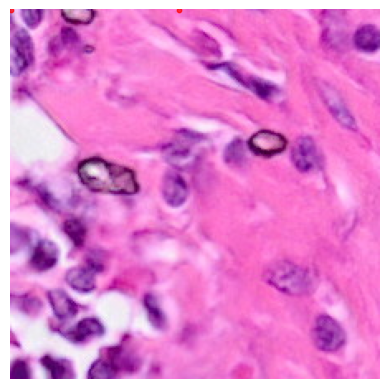

In [63]:
data = {"x_pixel": [spot_pxl_X, spot_array_x], "y_pixel": [spot_pxl_y, spot_array_y]}
spots_in_patch = pd.DataFrame(data)

x0, y0 = spot_pxl_X, spot_pxl_y
spots_in_patch["x_rel"] = spots_in_patch["x_pixel"] - x0
spots_in_patch["y_rel"] = spots_in_patch["y_pixel"] - y0



plt.imshow(patch_img)
plt.scatter(
    spots_in_patch["x_rel"],
    spots_in_patch["y_rel"],
    c="red", s=10, alpha=0.7
)
plt.axis("off")
plt.show()


In [64]:
spots_in_patch

,x_pixel,y_pixel,x_rel,y_rel
0,44268,39511,0,0
1,44370,39511,102,0


In [68]:
tissue_pos_array = tissue_pos[(tissue_pos["array_col"] == 0) & (tissue_pos["array_row"] == 0)]
tissue_pos_array

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,63975.247443,44268.960124


In [ ]:
pxl_x = tissue_pos["pxl_col_in_fullres"].min()
pxl_y = tissue_pos["pxl_row_in_fullres"].max()
print(pxl_x, pxl_y)

44268.96012379498 64076.159171259045


In [ ]:
tissue_pos_pxl = tissue_pos[(tissue_pos[""])]

# Next try checking coordinates in pixel and array form 

In [15]:
import pandas as pd
person = "CRC_P5"

tissue_pos = pd.read_parquet(f"data/{person}/output/binned_outputs/square_002um/spatial/tissue_positions.parquet")

In [16]:
# Check only for array coordinates 
# x = col
# y = row
array_x_min = tissue_pos["array_col"].min()
array_y_min = tissue_pos["array_row"].min()
array_x_max = tissue_pos["array_col"].max()
array_y_max = tissue_pos["array_row"].max()

print("Min: ", array_x_min, array_y_min)
print("Max: ", array_x_max, array_y_max)

tissue_pos_array = tissue_pos[((tissue_pos["array_col"] == array_x_min) | (tissue_pos["array_col"] == array_x_max)) &
                               ((tissue_pos["array_row"] == array_y_min) | (tissue_pos["array_row"] == array_y_max))]

Min:  0 0
Max:  3349 3349


In [17]:
tissue_pos_array

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,63975.247443,44268.960124
3349,s_002um_00000_03349-1,1,0,3349,64076.159171,68734.296386
11219150,s_002um_03349_00000-1,1,3349,0,39511.750928,44370.408730
11222499,s_002um_03349_03349-1,0,3349,3349,39611.888844,68834.381554


In [13]:
# Now check only for pixel coordinates
# x = col
# y = row
pxl_x_min = tissue_pos["pxl_col_in_fullres"].min()
pxl_y_min = tissue_pos["pxl_row_in_fullres"].min()
pxl_x_max = tissue_pos["pxl_col_in_fullres"].max()
pxl_y_max = tissue_pos["pxl_row_in_fullres"].max()

print("Min: ", pxl_x_min, pxl_y_min)
print("Max: ", pxl_x_max, pxl_y_max)

tissue_pos_pxl = tissue_pos[(tissue_pos["pxl_col_in_fullres"] == pxl_x_min) | (tissue_pos["pxl_col_in_fullres"] == pxl_x_max) |
                               (tissue_pos["pxl_row_in_fullres"] == pxl_y_min) | (tissue_pos["pxl_row_in_fullres"] == pxl_y_max)]

Min:  -253.148794489166 12137.797400349906
Max:  24436.630813568463 36828.94892524755


In [14]:
tissue_pos_pxl

,barcode,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
0,s_002um_00000_00000-1,0,0,0,36602.550726,-253.148794
3349,s_002um_00000_03349-1,1,0,3349,36828.948925,24208.132968
11219150,s_002um_03349_00000-1,0,3349,0,12137.797400,-25.463248
11222499,s_002um_03349_03349-1,1,3349,3349,12362.559273,24436.630814
